In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_kddcup99
import matplotlib.pyplot as plt
import pandas as pd
ROLL_NUMBER = 2024573
rng = np.random.default_rng(seed = ROLL_NUMBER)

In [ ]:
kdd = fetch_kddcup99(subset = None, as_frame = True)

X = kdd.data.copy()

cat_cols = ['protocol_type', 'service', 'flag']

num_cols= [col for col in X.columns if col not in cat_cols]

X_num = X[num_cols].astype(np.float32)

X_cat = pd.get_dummies(X[cat_cols], dtype = np.float32)

X = pd.concat([X_num, X_cat], axis = 1)
print("Shape after encoding (one hot encoding categorical columns): ", X.shape)
constant_cols = X.columns[X.nunique(dropna=False)==1]

X = X.drop(columns = constant_cols)
print("Number of constant columns removed:  ", len(constant_cols))

X = (X - X.min())/(X.max() - X.min())

D = X.to_numpy(dtype = np.float32)
# either normal or attack (binary target variable)
y = (kdd.target!=b'normal.').to_numpy(dtype=np.float32)

n,d = D.shape

print("n : ", n)
print("d : ", d)
print("Dataset shape (D):", D.shape)
print("y Shape: ", y.shape)
print("Range of Dataset", D.min(), D.max())
print("Attack proportion: ", y.mean())

Shape after encoding (one hot encoding categorical columns):  (494021, 118)
Number of constant columns removed:   2
n :  494021
d :  116
Dataset shape (D): (494021, 116)
y Shape:  (494021,)
Range of Dataset 0.0 1.0
Attack proportion:  0.8030893


In [ ]:
import time
import numpy as np

start = time.perf_counter()

b,residuals, rank, singular_values = np.linalg.lstsq(D, y, rcond = None)

full_time = time.perf_counter()-start

v = D@b - y

full_loss = np.sum(v.astype(np.float64)**2)

print("Rank of D: ", rank)
print("Full Least Squares Loss:", full_loss)
print("Time to compute b: ", full_time,"seconds")
print("Shape of b: ", b.shape)


Rank of D:  113
Full Least Squares Loss: 2949.788819474225
Time to compute b:  5.701851136999949 seconds
Shape of b:  (116,)


In [ ]:
def count_sketch(D, y, m, rng):
  n,d = D.shape
  # random bucket for each of the n row
  h = rng.integers(0, m, size = n)

  signs = rng.choice([-1,1], size = n)

  SD = np.zeros((m,d), dtype = np.float64)
  Sy = np.zeros(m, dtype = np.float64)

  chunk_size = 10000
  for start in range(0,n, chunk_size):
    end = min(start+chunk_size, n)

    np.add.at(SD, h[start:end], signs[start:end, None]* D[start:end])

    np.add.at(Sy, h[start:end], signs[start:end]*y[start:end])

  return SD, Sy

m_vals = [50,100,200,500,1000,2000,5000]

repetitions =5

results = []
rng_b = np.random.default_rng(seed = ROLL_NUMBER)
for m in m_vals:
  print("Running m = ",m)
  for rep in range(repetitions):
    start = time.perf_counter()

    SD, Sy = count_sketch(D, y, m , rng_b)

    a_red, _,_,_ = np.linalg.lstsq(SD, Sy, rcond = None)

    time_taken = time.perf_counter()-start

    residual_original = D@a_red - y
    original_loss = np.sum(residual_original**2)

    ratio = original_loss/full_loss

    residual_sketch = SD@a_red -Sy
    sketched_loss = np.sum(residual_sketch ** 2)

    results.append({
        "m" : m,
        "rep_count": rep,
        "time_taken" : time_taken,
        "original_loss" : original_loss,
        "sketched_loss" : sketched_loss,
        "ratio" : ratio
    })
results_df = pd.DataFrame(results)

summary= results_df.groupby("m").agg(
    mean_original_loss = ("original_loss", "mean"),
    mean_sketched_loss = ("sketched_loss", "mean"),
    mean_ratio = ("ratio", "mean"),
    mean_time = ("time_taken", "mean"),
    min_ratio = ("ratio", "min"),
    max_ratio = ("ratio", "max")
)
print(summary.round(4).to_string())

Running m =  50
Running m =  100
Running m =  200
Running m =  500
Running m =  1000
Running m =  2000
Running m =  5000
      mean_original_loss  mean_sketched_loss  mean_ratio  mean_time  min_ratio  max_ratio
m                                                                                        
50            10182.0547              0.0000      3.4518     0.9994     2.6044     4.8006
100           36850.7412              0.0000     12.4927     1.2285     7.5770    19.8584
200            6373.8590           1259.5683      2.1608     1.2433     1.9868     2.3245
500            3906.4644           2237.0710      1.3243     1.2434     1.2545     1.4066
1000           3341.5011           2691.7084      1.1328     1.4418     1.1019     1.1488
2000           3136.6615           2808.5997      1.0634     1.3902     1.0559     1.0690
5000           3025.5263           2853.9465      1.0257     1.1830     1.0236     1.0278


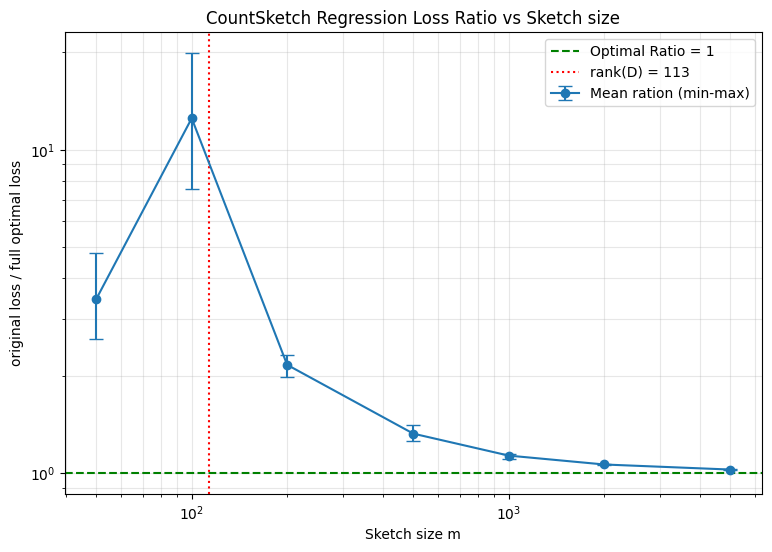

In [ ]:
m_arr= summary.index.to_numpy()
mean_ratios = summary['mean_ratio'].to_numpy()
min_ratios = summary['min_ratio'].to_numpy()
max_ratios = summary['max_ratio'].to_numpy()

errors = [mean_ratios - min_ratios, max_ratios- mean_ratios]

plt.figure(figsize = (9,6))

plt.errorbar(m_arr, mean_ratios, yerr = errors, fmt = "o-", capsize = 5, label = "Mean ration (min-max)")

plt.axhline(y =1, color  = "green", linestyle = '--', label = "Optimal Ratio = 1")
plt.axvline(x = rank, color = 'red', linestyle = ":", label =f"rank(D) = {rank}")

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Sketch size m')
plt.ylabel("original loss / full optimal loss")
plt.title("CountSketch Regression Loss Ratio vs Sketch size")

plt.legend()
plt.grid(True, which = "both", alpha = 0.3)
plt.show()

In [ ]:
timing_summary = summary[["mean_time"]].copy()

timing_summary["full_time"] = full_time

timing_summary["speedup"] = (full_time/timing_summary["mean_time"])

timing_summary["time_saved%"] = (1 - timing_summary["mean_time"]/full_time)*100

print("Full Least Squares Time: ", full_time, "seconds")
print("Timing comparision:")
print(timing_summary.round(4).to_string())



Full Least Squares Time:  5.701851136999949 seconds
Timing comparision:
      mean_time  full_time  speedup  time_saved%
m                                               
50       0.9994     5.7019   5.7055      82.4729
100      1.2285     5.7019   4.6414      78.4545
200      1.2433     5.7019   4.5862      78.1952
500      1.2434     5.7019   4.5857      78.1930
1000     1.4418     5.7019   3.9548      74.7143
2000     1.3902     5.7019   4.1015      75.6189
5000     1.1830     5.7019   4.8199      79.2528


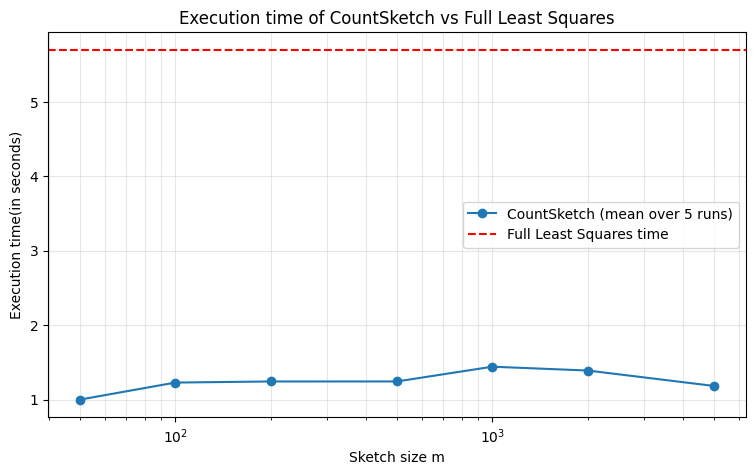

In [ ]:
plt.figure(figsize = (9,5))
plt.plot(timing_summary.index, timing_summary["mean_time"], marker = 'o', label = "CountSketch (mean over 5 runs)")
plt.axhline(full_time, color = "red", linestyle ='--', label ='Full Least Squares time')

plt.xscale("log")
plt.xlabel("Sketch size m")
plt.ylabel("Execution time(in seconds)")
plt.title("Execution time of CountSketch vs Full Least Squares")
plt.legend()
plt.grid(True, which = "both", alpha = 0.3)
plt.show()

In [ ]:
rng_d = np.random.default_rng(ROLL_NUMBER)

v = np.asarray(D@b -y, dtype = np.float64)

norm_v_sq = np.sum(v**2)

m_vals = [50,500,5000]

repitions = 100

results = {}

for m in m_vals:
  ratios = []

  for rep in range(repitions):
    # we draw a new count sketch
    h = rng_d.integers(0, m, size = (len(v)))
    signs = rng_d.choice([-1,1], size = len(v))

    Sv = np.bincount(h, weights = signs*v, minlength = m)

    ratio = np.sum(Sv**2)/norm_v_sq
    ratios.append(ratio)
  results[m] = np.array(ratios)

summary=  pd.DataFrame({
    "m":m_vals,
    "mean": [results[m].mean() for m in m_vals],
    "std": [results[m].std() for m in m_vals]
})

print(summary.round(4).to_string())

      m    mean     std
0    50  0.9894  0.1842
1   500  1.0005  0.0596
2  5000  0.9991  0.0202


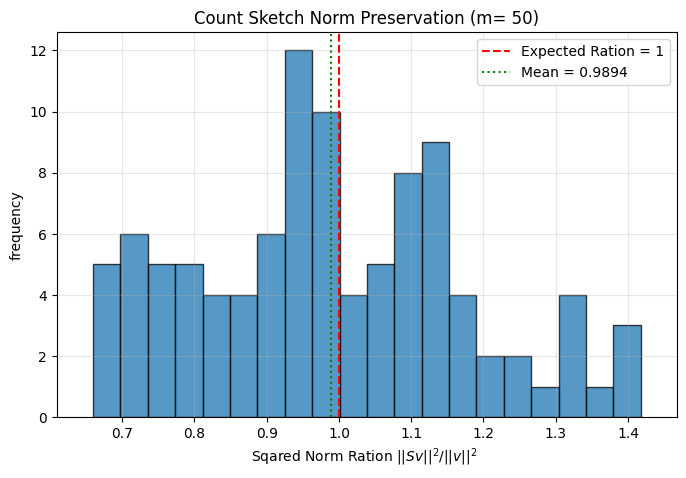

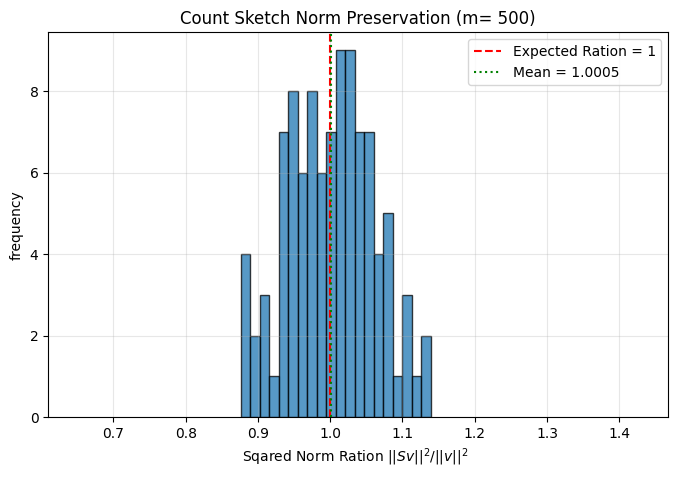

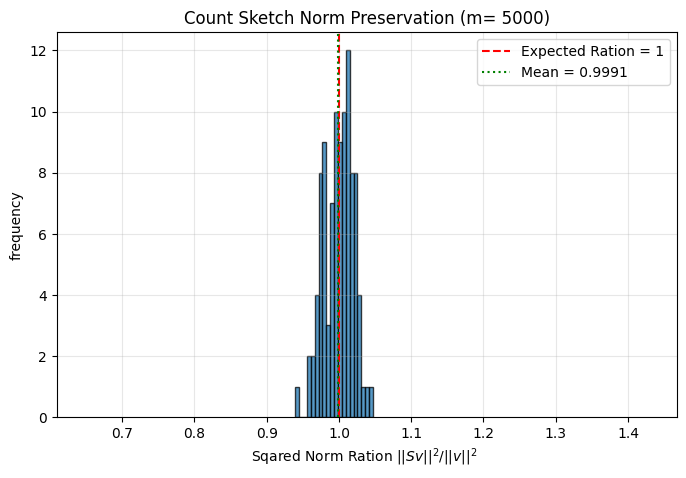

In [ ]:
all_ratios=np.concatenate(list(results.values()))

xmin = min(all_ratios.min(), 1) - 0.05
xmax = max(all_ratios.max(), 1) + 0.05

for m in m_vals:
  ratios = results[m]
  plt.figure(figsize = (8,5))
  plt.hist(ratios, bins = 20, edgecolor= "black", alpha = 0.75)
  plt.axvline(1, color = "red", linestyle="--", label = "Expected Ration = 1")

  plt.axvline(ratios.mean(), color = "green", linestyle = ":", label = f"Mean = {ratios.mean():.4f}")
  plt.xlim(xmin, xmax)

  plt.xlabel("Sqared Norm Ration $|| Sv||^2/||v||^2$  ")
  plt.ylabel("frequency")
  plt.title(f"Count Sketch Norm Preservation (m= {m})")

  plt.legend()
  plt.grid(alpha   =0.3)
  plt.show()


In [ ]:
rng_e = np.random.default_rng(2024573)

indices = rng_e.choice(n, size = 50000, replace = False)

D_new = np.ascontiguousarray(D[indices], dtype = np.float32)
y_new = np.asarray(y[indices], dtype = np.float32)

b_new, _, rank_new, _ = np.linalg.lstsq(D_new, y_new, rcond = None)

residual_new = D_new@b_new - y_new

full_loss_new = np.sum(residual_new**2, dtype = np.float64)

print("D shape: ", D_new.shape)
print("Rank of the new Dataset : ", rank_new)
print("Optimal Dataset Subset Loss: ", full_loss_new)

D shape:  (50000, 116)
Rank of the new Dataset :  109
Optial Dataset Subset Loss:  221.8452035579391


In [ ]:
m = 500
repetitions = 5
n_new= len(y_new)

results= []

for method in ["CountSketch", "Gaussian"]:
  for rep in range(repetitions):
    start=time.perf_counter()

    if method == "CountSketch":
      h = rng_e.integers(0,m, size = n_new)

      signs = rng.choice([-1,1], size = n_new)

      SD = np.zeros((m, D_new.shape[1]), dtype = np.float32)
      Sy = np.zeros(m, dtype = np.float32)

      np.add.at(SD, h, signs[:, None]*D_new)
      np.add.at(Sy, h, signs*y_new)

    else:
      S = rng.standard_normal((m,n_new), dtype = np.float32) / np.sqrt(m)
      SD = S@D_new
      Sy = S@y_new
      del S

    sketch_time= time.perf_counter()-start

    a_reduced, _, _, _ = np.linalg.lstsq(SD, Sy, rcond = None)

    total_time = time.perf_counter()-start

    residual = D_new@a_reduced - y_new
    original_loss = np.sum(residual**2, dtype=np.float64)

    ratio = original_loss / full_loss_new

    results.append({
        "method": method,
        "rep_count": rep+1,
        "sketch_time": sketch_time,
        "original_loss": original_loss,
        "ratio": ratio,
        "total_time": total_time
    })

results_df = pd.DataFrame(results)

summary = results_df.groupby("method").agg(
    mean_sketch_time = ("sketch_time", "mean"),
    std_ratio = ("ratio", "std"),
    mean_ratio = ("ratio", "mean"),
    mean_total_time = ("total_time", "mean"),
)
print(summary.round(4).to_string())

             mean_sketch_time  std_ratio  mean_ratio  mean_total_time
method                                                               
CountSketch            0.8754     0.0456      1.2567           0.9754
Gaussian               0.9815     0.0200      1.2911           0.9934
